# Análise genérica do log `oscillator1` (LLM-SR)

Este notebook analisa **um diretório de log escolhido na célula de configuração**. Ele lê as amostras e scores, escolhe a melhor candidata válida, tenta interpretar com segurança a função gerada, reajusta seus parâmetros apenas no treino e compara as previsões em `train`, `test_id` e `test_ood` com a equação física. Também tenta ajustar PySR e gplearn como referências opcionais.

## Como interpretar

Os JSONs do LLM-SR guardam o código e o score, mas não os parâmetros otimizados usados na busca. Por isso, o notebook estima novos parâmetros para a candidata no treino e usa esses valores fixos nos testes. Isso não reproduz exatamente o score original. A interpretação da função é restrita: o código gerado **não é executado com `exec`**; um interpretador AST aceita operações aritméticas, chamadas NumPy selecionadas, atribuições, retornos e condicionais simples. Se uma amostra usar uma construção fora dessa gramática, ela é marcada como não interpretável e não interrompe o restante do notebook.

Para analisar outro log, altere `RUN_DIR` na primeira célula de configuração. O valor pode ser um caminho relativo à raiz do repositório ou absoluto.


In [24]:
from pathlib import Path
import ast
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data/oscillator1").is_dir() and (candidate / "logs").is_dir():
            return candidate
    raise FileNotFoundError("Não encontrei a raiz do repositório LLM-SR.")

ROOT = find_repo_root(Path.cwd().resolve())
# Altere para qualquer pasta de execução, por exemplo:
# RUN_DIR = ROOT / "logs" / "oscillator1_qwen25"
RUN_DIR = ROOT / "logs" / "oscillator1_mistral_seed7_rag"
RUN_DIR = Path(RUN_DIR)
if not RUN_DIR.is_absolute():
    RUN_DIR = ROOT / RUN_DIR
SAMPLES_DIR = RUN_DIR / "samples"
DATA_DIR = ROOT / "data" / "oscillator1"
FIT_CLASSIC_BASELINES = True  # PySR/gplearn são opcionais e podem levar algum tempo.

print("Execução analisada:", RUN_DIR)
if not RUN_DIR.is_dir():
    available = sorted(p.name for p in (ROOT / "logs").glob("oscillator1*") if p.is_dir())
    raise FileNotFoundError(f"Diretório de log não encontrado. Logs disponíveis: {available}")
plt.style.use("seaborn-v0_8-whitegrid")


Execução analisada: /home/ymws/Documentos/llm-sr/LLM-SR/logs/oscillator1_mistral_seed7_rag


## 1. Dados do benchmark e amostras do log

In [25]:
sets = {name: pd.read_csv(DATA_DIR / f"{name}.csv") for name in ["train", "test_id", "test_ood"]}
required = {"x", "v", "a"}
for name, df in sets.items():
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name}: colunas ausentes: {missing}")

records, read_errors = [], []
for path in sorted(SAMPLES_DIR.glob("samples_*.json")):
    try:
        obj = json.loads(path.read_text(encoding="utf-8"))
        records.append({"arquivo": path.name, "ordem": obj.get("sample_order"),
                        "score": pd.to_numeric(obj.get("score"), errors="coerce"),
                        "function": obj.get("function", "")})
    except (OSError, json.JSONDecodeError) as exc:
        read_errors.append((path.name, str(exc)))
samples = pd.DataFrame(records, columns=["arquivo", "ordem", "score", "function"])
if samples.empty:
    raise FileNotFoundError(f"Não encontrei samples_*.json em {SAMPLES_DIR}")
samples["ordem"] = pd.to_numeric(samples["ordem"], errors="coerce")
samples["score"] = pd.to_numeric(samples["score"], errors="coerce")
valid_samples = samples.dropna(subset=["score"]).copy()
print(f"Amostras: {len(samples):,} | scores válidos: {len(valid_samples):,} | score ausente/inválido: {samples.score.isna().sum():,}")
print(f"JSONs ignorados por erro de leitura: {len(read_errors)}")
if valid_samples.empty:
    raise ValueError("O log não contém nenhuma amostra com score numérico.")
display(pd.DataFrame({"n": {k: len(v) for k,v in sets.items()},
                      "score válido": {k: int(samples.score.notna().sum()) for k in sets}}))


Amostras: 10,001 | scores válidos: 3,697 | score ausente/inválido: 6,304
JSONs ignorados por erro de leitura: 0


,n,score válido
train,10000,3697
test_id,10000,3697
test_ood,10000,3697


## 2. Resumo de scores e progresso da busca

,count,mean,std,min,25%,50%,75%,90%,99%,max
score,3697.0,-1.318429e+21,8.016438e+22,-4.874232e+24,-0.000423,-0.000418,-0.000398,-0.000018,-7.292850e-09,-2.141483e-10


Melhor amostra: samples_9479.json | ordem=9479 | score=-2.14148312e-10
Convenção esperada: score = -MSE no treino; maior (mais próximo de zero) é melhor.


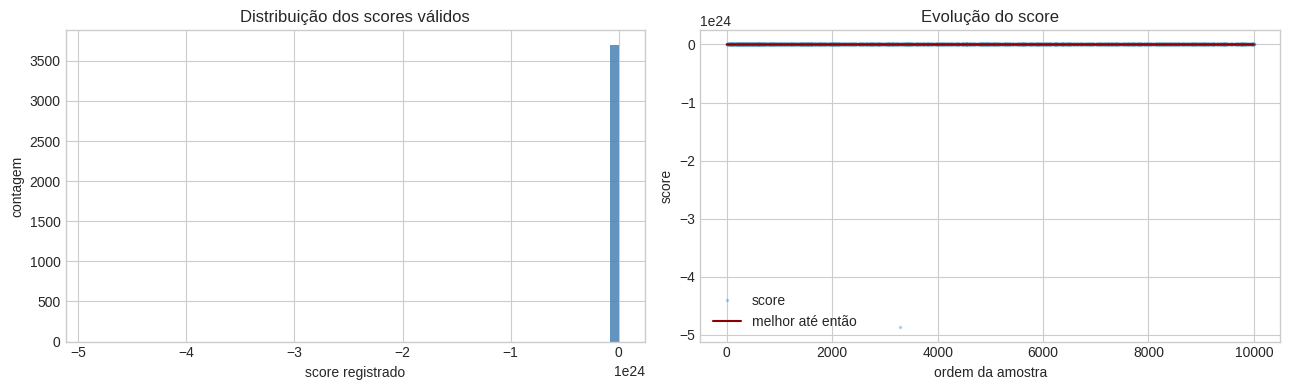


Código da melhor candidata registrada:
def equation(x: np.ndarray, v: np.ndarray, params: np.ndarray) -> np.ndarray:
    """ Mathematical function for acceleration in a damped nonlinear oscillator

    Args:
        x: A numpy array representing observations of current position.
        v: A numpy array representing observations of velocity.
        params: Array of numeric constants or parameters to be optimized

    Return:
        A numpy array representing acceleration as the result of applying the mathematical function to the inputs.
    """
    """ Mathematical function for acceleration in a damped nonlinear oscillator
    
    Args:
        x: A numpy array representing observations of current position.
        v: A numpy array representing observations of velocity.
        params: Array of numeric constants or parameters to be optimized
    
    Return:
        A numpy array representing acceleration as the result of applying the mathematical function to the inputs.
    """
  

In [26]:
display(valid_samples.score.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame().T)
best = valid_samples.loc[valid_samples.score.idxmax()]
print(f"Melhor amostra: {best['arquivo']} | ordem={best['ordem']} | score={best['score']:.10g}")
print("Convenção esperada: score = -MSE no treino; maior (mais próximo de zero) é melhor.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(valid_samples.score, bins=60, color="steelblue", alpha=.85)
axes[0].set(title="Distribuição dos scores válidos", xlabel="score registrado", ylabel="contagem")
ordered = valid_samples.dropna(subset=["ordem"]).sort_values("ordem")
axes[1].plot(ordered["ordem"], ordered["score"], ".", alpha=.25, ms=3, label="score")
axes[1].plot(ordered["ordem"], ordered["score"].cummax(), color="darkred", lw=1.5, label="melhor até então")
axes[1].set(title="Evolução do score", xlabel="ordem da amostra", ylabel="score")
axes[1].legend()
plt.tight_layout(); plt.show()

print("\nCódigo da melhor candidata registrada:")
print(best["function"])


## 3. Interpretador seguro do código candidato

A próxima célula traduz uma gramática limitada do Python para operações NumPy. Ela não usa `eval`/`exec`. A lista de funções NumPy aceitas é explícita; se aparecer uma operação fora da lista, o notebook reporta a limitação e pula somente a avaliação numérica da candidata.


In [27]:
NP_FUNCS = {
    "sin": np.sin, "cos": np.cos, "tan": np.tan, "exp": np.exp,
    "log": np.log, "sqrt": np.sqrt, "abs": np.abs, "absolute": np.abs,
    "sign": np.sign, "tanh": np.tanh, "sinh": np.sinh, "cosh": np.cosh,
    "minimum": np.minimum, "maximum": np.maximum, "where": np.where,
}

BINOPS = {ast.Add: lambda a,b:a+b, ast.Sub: lambda a,b:a-b, ast.Mult: lambda a,b:a*b,
          ast.Div: lambda a,b:a/b, ast.Pow: lambda a,b:a**b, ast.Mod: lambda a,b:a%b}
CMPOPS = {ast.Gt: lambda a,b:a>b, ast.GtE: lambda a,b:a>=b, ast.Lt: lambda a,b:a<b,
          ast.LtE: lambda a,b:a<=b, ast.Eq: lambda a,b:a==b, ast.NotEq: lambda a,b:a!=b}

class UnsupportedCandidate(ValueError):
    pass

def eval_expr(node, env):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float, bool)):
        return node.value
    if isinstance(node, ast.Name):
        if node.id in env: return env[node.id]
        if node.id == "pi": return np.pi
        raise UnsupportedCandidate(f"Nome não permitido: {node.id}")
    if isinstance(node, ast.Attribute):
        if isinstance(node.value, ast.Name) and node.value.id == "np" and node.attr == "pi": return np.pi
        raise UnsupportedCandidate("Atributo não permitido")
    if isinstance(node, ast.BinOp) and type(node.op) in BINOPS:
        return BINOPS[type(node.op)](eval_expr(node.left, env), eval_expr(node.right, env))
    if isinstance(node, ast.UnaryOp):
        value = eval_expr(node.operand, env)
        if isinstance(node.op, ast.USub): return -value
        if isinstance(node.op, ast.UAdd): return value
        if isinstance(node.op, ast.Not): return not value
    if isinstance(node, ast.Subscript):
        value = eval_expr(node.value, env)
        index = eval_expr(node.slice, env)
        return value[index]
    if isinstance(node, ast.Call):
        args = [eval_expr(arg, env) for arg in node.args]
        if isinstance(node.func, ast.Name) and node.func.id == "len":
            return len(args[0])
        if isinstance(node.func, ast.Attribute) and isinstance(node.func.value, ast.Name) and node.func.value.id == "np":
            fn = NP_FUNCS.get(node.func.attr)
            if fn is None: raise UnsupportedCandidate(f"np.{node.func.attr} não está na lista permitida")
            return fn(*args)
        if isinstance(node.func, ast.Name) and node.func.id in NP_FUNCS:
            return NP_FUNCS[node.func.id](*args)
        raise UnsupportedCandidate("Chamada de função não permitida")
    if isinstance(node, ast.Compare):
        left = eval_expr(node.left, env)
        for op, comparator in zip(node.ops, node.comparators):
            if type(op) not in CMPOPS: raise UnsupportedCandidate("Comparação não suportada")
            right = eval_expr(comparator, env)
            if not bool(np.all(CMPOPS[type(op)](left, right))): return False
            left = right
        return True
    if isinstance(node, ast.BoolOp):
        vals = [bool(eval_expr(v, env)) for v in node.values]
        if isinstance(node.op, ast.And): return all(vals)
        if isinstance(node.op, ast.Or): return any(vals)
    raise UnsupportedCandidate(f"Construção não suportada: {type(node).__name__}")

def run_statements(statements, env):
    for stmt in statements:
        if isinstance(stmt, ast.Expr) and isinstance(stmt.value, ast.Constant) and isinstance(stmt.value.value, str):
            continue  # docstring
        if isinstance(stmt, ast.Assign):
            value = eval_expr(stmt.value, env)
            for target in stmt.targets:
                if not isinstance(target, ast.Name): raise UnsupportedCandidate("Atribuição só aceita nomes simples")
                env[target.id] = value
        elif isinstance(stmt, ast.AnnAssign):
            if stmt.value is not None:
                if not isinstance(stmt.target, ast.Name): raise UnsupportedCandidate("Atribuição anotada não suportada")
                env[stmt.target.id] = eval_expr(stmt.value, env)
        elif isinstance(stmt, ast.AugAssign) and isinstance(stmt.target, ast.Name) and type(stmt.op) in BINOPS:
            env[stmt.target.id] = BINOPS[type(stmt.op)](env[stmt.target.id], eval_expr(stmt.value, env))
        elif isinstance(stmt, ast.If):
            branch = stmt.body if eval_expr(stmt.test, env) else stmt.orelse
            result = run_statements(branch, env)
            if result is not _NO_RETURN: return result
        elif isinstance(stmt, ast.Return):
            return eval_expr(stmt.value, env) if stmt.value is not None else None
        elif isinstance(stmt, ast.Pass):
            continue
        else:
            raise UnsupportedCandidate(f"Instrução não suportada: {type(stmt).__name__}")
    return _NO_RETURN

_NO_RETURN = object()
def candidate_function(source):
    tree = ast.parse(source)
    functions = [node for node in tree.body if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))]
    if len(functions) != 1 or isinstance(functions[0], ast.AsyncFunctionDef):
        raise UnsupportedCandidate("Esperava exatamente uma função síncrona")
    fn = functions[0]
    param_indices = []
    for node in ast.walk(fn):
        if (isinstance(node, ast.Subscript) and isinstance(node.value, ast.Name)
                and node.value.id == "params" and isinstance(node.slice, ast.Constant)
                and isinstance(node.slice.value, int)):
            param_indices.append(node.slice.value)
    n_params = max(param_indices, default=-1) + 1
    if n_params > 64:
        raise UnsupportedCandidate(f"Número de parâmetros inesperadamente alto: {n_params}")
    def predict(x, v, params):
        env = {"x": np.asarray(x), "v": np.asarray(v), "params": np.asarray(params), "np": np}
        result = run_statements(fn.body, env)
        if result is _NO_RETURN: raise UnsupportedCandidate("A função não contém return executável")
        arr = np.asarray(result, dtype=float)
        if arr.ndim == 0: arr = np.full(np.broadcast(np.asarray(x), np.asarray(v)).shape, float(arr))
        return np.broadcast_to(arr, np.broadcast(np.asarray(x), np.asarray(v)).shape).astype(float)
    return predict, n_params

try:
    candidate_predict, n_candidate_params = candidate_function(str(best["function"]))
    print(f"Candidata interpretável; parâmetros ajustáveis detectados: {n_candidate_params}")
except Exception as exc:
    candidate_predict, n_candidate_params = None, 0
    candidate_parse_error = str(exc)
    print("Não foi possível interpretar a melhor candidata:", candidate_parse_error)


Candidata interpretável; parâmetros ajustáveis detectados: 10


## 4. Reajuste da candidata e avaliação ID/OOD

In [28]:
from scipy.optimize import least_squares

candidate_fit = None
candidate_metrics = []
if candidate_predict is None:
    print("A comparação numérica da candidata foi pulada; os demais resultados continuam disponíveis.")
elif n_candidate_params == 0:
    print("A candidata não contém parâmetros ajustáveis. Será avaliada diretamente nos dados.")
    candidate_fit = np.empty(0)
else:
    fit_df = sets["train"]
    # Subamostra determinística opcional para limitar o custo da otimização.
    if len(fit_df) > 4000:
        fit_df = fit_df.sample(n=4000, random_state=0)
    xfit, vfit, yfit = (fit_df[c].to_numpy() for c in ["x", "v", "a"])
    rng = np.random.default_rng(0)
    starts = [np.zeros(n_candidate_params), np.ones(n_candidate_params) * 0.5,
              rng.normal(0, 0.5, size=n_candidate_params)]
    def residuals(params):
        try:
            pred = candidate_predict(xfit, vfit, params)
            residual = np.asarray(pred, dtype=float).reshape(-1) - yfit
            if residual.shape != yfit.shape or not np.all(np.isfinite(residual)):
                return np.full_like(yfit, 1e6, dtype=float)
            return residual
        except Exception:
            return np.full_like(yfit, 1e6, dtype=float)
    fits = []
    for start in starts:
        try:
            fits.append(least_squares(residuals, start, max_nfev=300, method="trf"))
        except Exception as exc:
            print("Uma inicialização da otimização falhou:", repr(exc))
    if fits:
        candidate_fit = min(fits, key=lambda result: float(np.mean(result.fun**2))).x
        print("Parâmetros reajustados no treino (não são os parâmetros originais do log):")
        display(pd.DataFrame({"índice": np.arange(n_candidate_params), "valor": candidate_fit}))
    else:
        print("A otimização não encontrou uma solução utilizável.")

if candidate_predict is not None:
    for split, df in sets.items():
        try:
            pred = candidate_predict(df.x.to_numpy(), df.v.to_numpy(),
                                     candidate_fit if candidate_fit is not None else np.empty(0))
            mse = mean_squared_error(df.a, pred)
            candidate_metrics.append({"modelo": "LLM-SR (melhor candidata; reajustada no treino)",
                                      "conjunto": split, "MSE": mse, "RMSE": np.sqrt(mse),
                                      "MAE": mean_absolute_error(df.a, pred), "R²": r2_score(df.a, pred)})
        except Exception as exc:
            print(f"Falha ao avaliar candidata em {split}:", repr(exc))
    if candidate_metrics:
        display(pd.DataFrame(candidate_metrics).set_index("conjunto").round(8))


Parâmetros reajustados no treino (não são os parâmetros originais do log):


,índice,valor
0,0,0.276725
1,1,0.000405
2,2,0.500041
3,3,0.226380
4,4,0.273616
5,5,0.000230
6,6,0.000003
7,7,0.088899
8,8,-2.251838
9,9,-0.000102


,modelo,MSE,RMSE,MAE,R²
conjunto,,,,,
train,LLM-SR (melhor candidata; reajustada no treino),0.000000,0.000014,0.000012,1.000000
test_id,LLM-SR (melhor candidata; reajustada no treino),0.000000,0.000014,0.000012,1.000000
test_ood,LLM-SR (melhor candidata; reajustada no treino),0.000002,0.001278,0.000784,0.999785


## Melhor equação encontrada

A célula abaixo imprime em destaque o código da melhor amostra pelo score e uma forma matemática com os parâmetros **reajustados no treino**. Esses parâmetros são novos ajustes, porque o JSON original não os salvou.


In [29]:
import sympy as sp


def best_equation_symbolic(source, params):
    """Converte a gramática aritmética segura da candidata em SymPy."""
    tree = ast.parse(source)
    fn = next(node for node in tree.body if isinstance(node, ast.FunctionDef))
    sx, sv = sp.symbols("x v", real=True)
    env = {"x": sx, "v": sv, "params": np.asarray(params), "pi": sp.pi}
    funcs = {"sin": sp.sin, "cos": sp.cos, "tan": sp.tan, "exp": sp.exp,
             "log": sp.log, "sqrt": sp.sqrt, "abs": sp.Abs, "absolute": sp.Abs,
             "sign": sp.sign, "tanh": sp.tanh, "sinh": sp.sinh, "cosh": sp.cosh}
    ops = {ast.Add: lambda a,b:a+b, ast.Sub: lambda a,b:a-b, ast.Mult: lambda a,b:a*b,
           ast.Div: lambda a,b:a/b, ast.Pow: lambda a,b:a**b, ast.Mod: lambda a,b:sp.Mod(a,b)}
    def value(node, scope):
        if isinstance(node, ast.Constant): return node.value
        if isinstance(node, ast.Name):
            if node.id in scope: return scope[node.id]
            raise UnsupportedCandidate(f"Nome simbólico não suportado: {node.id}")
        if isinstance(node, ast.Attribute) and isinstance(node.value, ast.Name) and node.value.id == "np" and node.attr == "pi":
            return sp.pi
        if isinstance(node, ast.Subscript): return value(node.value, scope)[value(node.slice, scope)]
        if isinstance(node, ast.BinOp) and type(node.op) in ops: return ops[type(node.op)](value(node.left,scope),value(node.right,scope))
        if isinstance(node, ast.UnaryOp):
            val=value(node.operand,scope)
            if isinstance(node.op,ast.USub): return -val
            if isinstance(node.op,ast.UAdd): return val
        if isinstance(node, ast.Call):
            if isinstance(node.func, ast.Name) and node.func.id == "len": return len(value(node.args[0],scope))
            if isinstance(node.func, ast.Attribute) and isinstance(node.func.value,ast.Name) and node.func.value.id == "np":
                fn_sym=funcs.get(node.func.attr)
                if fn_sym is None: raise UnsupportedCandidate(f"np.{node.func.attr} não tem formatação simbólica")
                return fn_sym(*(value(a,scope) for a in node.args))
            if isinstance(node.func, ast.Name) and node.func.id in funcs:
                return funcs[node.func.id](*(value(a,scope) for a in node.args))
        if isinstance(node, ast.Compare):
            left=value(node.left,scope); right=value(node.comparators[0],scope)
            cmp={ast.Gt:lambda:left>right,ast.GtE:lambda:left>=right,ast.Lt:lambda:left<right,
                 ast.LtE:lambda:left<=right,ast.Eq:lambda:left==right,ast.NotEq:lambda:left!=right}
            if len(node.ops)==1 and type(node.ops[0]) in cmp: return cmp[type(node.ops[0])]()
        if isinstance(node, ast.BoolOp):
            vals=[bool(value(v,scope)) for v in node.values]
            return all(vals) if isinstance(node.op,ast.And) else any(vals)
        raise UnsupportedCandidate(f"Expressão não formatável simbolicamente: {type(node).__name__}")
    def statements(body, scope):
        for stmt in body:
            if isinstance(stmt,ast.Expr) and isinstance(stmt.value,ast.Constant) and isinstance(stmt.value.value,str): continue
            if isinstance(stmt,ast.Assign):
                expr=value(stmt.value,scope)
                for target in stmt.targets:
                    if not isinstance(target,ast.Name): raise UnsupportedCandidate("Alvo de atribuição não simples")
                    scope[target.id]=expr
            elif isinstance(stmt,ast.AnnAssign) and stmt.value is not None and isinstance(stmt.target,ast.Name):
                scope[stmt.target.id]=value(stmt.value,scope)
            elif isinstance(stmt,ast.AugAssign) and isinstance(stmt.target,ast.Name) and type(stmt.op) in ops:
                scope[stmt.target.id]=ops[type(stmt.op)](scope[stmt.target.id],value(stmt.value,scope))
            elif isinstance(stmt,ast.If):
                condition=value(stmt.test,scope)
                if not isinstance(condition,(bool,np.bool_)):
                    raise UnsupportedCandidate("Condicional dependente de x/v não pode ser resumida como uma única fórmula nesta impressão")
                result=statements(stmt.body if condition else stmt.orelse,scope)
                if result is not None: return result
            elif isinstance(stmt,ast.Return): return value(stmt.value,scope) if stmt.value else sp.nan
            elif isinstance(stmt,ast.Pass): continue
            else: raise UnsupportedCandidate(f"Instrução não formatável: {type(stmt).__name__}")
        return None
    result=statements(fn.body,env)
    if result is None: raise UnsupportedCandidate("Não encontrei uma expressão de retorno")
    return sx,sv,sp.simplify(result)

print("=" * 88)
print("🏆 MELHOR EQUAÇÃO LLM-SR PELO SCORE")
print(f"Amostra: {best['arquivo']} | ordem: {best['ordem']} | score: {best['score']:.10g}")
print("Score maior (mais próximo de zero) corresponde a menor MSE registrado no treino.")
if candidate_predict is not None and candidate_fit is not None:
    try:
        sx,sv,best_expr=best_equation_symbolic(str(best["function"]),candidate_fit)
        print("\nEquação com parâmetros reajustados no conjunto train:")
        print("a(x, v) =", sp.sstr(best_expr))
        print("\nParâmetros reajustados:")
        print({f"params[{i}]": float(value) for i,value in enumerate(candidate_fit)})
    except Exception as exc:
        print("Não consegui reduzir o código a uma fórmula simbólica única:", str(exc))
        print("Código da melhor amostra (usado pelo interpretador seguro):")
        print(best["function"])
else:
    print("A candidata não foi reajustada; código da melhor amostra:")
    print(best["function"])
print("=" * 88)


🏆 MELHOR EQUAÇÃO LLM-SR PELO SCORE
Amostra: samples_9479.json | ordem: 9479 | score: -2.14148312e-10
Score maior (mais próximo de zero) corresponde a menor MSE registrado no treino.

Equação com parâmetros reajustados no conjunto train:
a(x, v) = Piecewise((-(0.500040560535139*v**3 + 9.0356705171879e-6), Eq(x, 0)), (-0.500040560535139*v**3 - 0.499996637051113*v*x - 3.2635188632263e-6*v*x/Abs(x) - 0.000230260626825066*x**2 - 0.0888988572545416*sin(2.25183778053607*x + 0.000101639895177321) + 0.276724651654885 - 0.276724651654885*exp(-0.000405466907935588*Abs(x)), True))

Parâmetros reajustados:
{'params[0]': 0.2767246516548848, 'params[1]': 0.0004054669079355877, 'params[2]': 0.5000405605351395, 'params[3]': 0.2263804487411144, 'params[4]': 0.2736161883099986, 'params[5]': 0.00023026062682506623, 'params[6]': 3.263518863226304e-06, 'params[7]': 0.08889885725454155, 'params[8]': -2.2518377805360688, 'params[9]': -0.00010163989517732129}


## 5. Equação física verdadeira

In [30]:
TRUE_PARAMS = {"F": 0.8, "omega": 1.0, "alpha": 0.5, "beta": 0.2, "gamma": 0.5}
def oscillator1_ground_truth(x, v):
    p = TRUE_PARAMS
    return (p["F"] * np.sin(p["omega"] * x) - p["alpha"] * v**3
            - p["beta"] * x**3 - p["gamma"] * x*v - x*np.cos(x))

print("a = 0.8·sin(x) - 0.5·v³ - 0.2·x³ - 0.5·x·v - x·cos(x)")
truth_metrics = []
for split, df in sets.items():
    pred = oscillator1_ground_truth(df.x.to_numpy(), df.v.to_numpy())
    mse = mean_squared_error(df.a, pred)
    truth_metrics.append({"modelo": "equação física", "conjunto": split, "MSE": mse,
                          "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(df.a, pred),
                          "R²": r2_score(df.a, pred)})
truth_metrics = pd.DataFrame(truth_metrics)
display(truth_metrics.set_index("conjunto").round(10))


a = 0.8·sin(x) - 0.5·v³ - 0.2·x³ - 0.5·x·v - x·cos(x)


,modelo,MSE,RMSE,MAE,R²
conjunto,,,,,
train,equação física,0.0,0.0,0.0,1.0
test_id,equação física,0.0,0.0,0.0,1.0
test_ood,equação física,0.0,0.0,0.0,1.0


## 6. Comparação com PySR e gplearn (opcional)

In [31]:
baseline_records = []
baseline_equations = {}
X_train = sets["train"][["x", "v"]].to_numpy()
y_train = sets["train"]["a"].to_numpy()
if FIT_CLASSIC_BASELINES:
    try:
        from pysr import PySRRegressor
        pysr_model = PySRRegressor(
            niterations=100, populations=8, population_size=33, maxsize=20,
            binary_operators=["+", "-", "*"], unary_operators=["sin", "cos"],
            verbosity=0, random_state=0,
        )
        pysr_model.fit(X_train, y_train, variable_names=["x", "v"])
        baseline_equations["PySR"] = str(pysr_model.get_best()["equation"])
        for split, df in sets.items():
            pred = np.asarray(pysr_model.predict(df[["x", "v"]].to_numpy())).reshape(-1)
            mse = mean_squared_error(df.a, pred)
            baseline_records.append({"modelo":"PySR", "conjunto":split, "MSE":mse,
                                     "RMSE":np.sqrt(mse), "MAE":mean_absolute_error(df.a,pred),
                                     "R²":r2_score(df.a,pred)})
    except Exception as exc:
        print("PySR indisponível ou falhou:", repr(exc))
    try:
        from gplearn.genetic import SymbolicRegressor
        gp_model = SymbolicRegressor(population_size=500, generations=20,
            function_set=["add", "sub", "mul", "div", "sin", "cos"],
            metric="mse", parsimony_coefficient=0.001, random_state=0, n_jobs=-1, verbose=0)
        gp_model.fit(X_train, y_train)
        baseline_equations["gplearn"] = str(gp_model._program)
        for split, df in sets.items():
            pred = np.asarray(gp_model.predict(df[["x", "v"]].to_numpy())).reshape(-1)
            mse = mean_squared_error(df.a, pred)
            baseline_records.append({"modelo":"gplearn", "conjunto":split, "MSE":mse,
                                     "RMSE":np.sqrt(mse), "MAE":mean_absolute_error(df.a,pred),
                                     "R²":r2_score(df.a,pred)})
    except Exception as exc:
        print("gplearn indisponível ou falhou:", repr(exc))
else:
    print("Ajuste de PySR/gplearn desativado na configuração.")

all_metrics = pd.concat([truth_metrics,
                         pd.DataFrame(candidate_metrics),
                         pd.DataFrame(baseline_records)], ignore_index=True)
display(all_metrics.pivot(index="modelo", columns="conjunto", values=["RMSE", "MAE", "R²"]).round(8))
print("\nEquações dos baselines ajustados:")
for name, equation in baseline_equations.items(): print(f"{name}: {equation}")


/home/ymws/miniconda3/envs/sr-llm-integration/lib/python3.11/site-packages/pysr/sr.py:2413: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(
/home/ymws/miniconda3/envs/sr-llm-integration/lib/python3.11/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


RMSE                      \
conjunto                                          test_id  test_ood     train   
modelo                                                                          
LLM-SR (melhor candidata; reajustada no treino)  0.000014  0.001278  0.000014   
PySR                                             0.000446  0.025616  0.000446   
equação física                                   0.000000  0.000000  0.000000   
gplearn                                          0.031479  0.059712  0.031481   

                                                      MAE                      \
conjunto                                          test_id  test_ood     train   
modelo                                                                          
LLM-SR (melhor candidata; reajustada no treino)  0.000012  0.000784  0.000012   
PySR                                             0.000347  0.016001  0.000347   
equação física                                   0.000000  0.000000  0.000000   
gplearn                                          0.023072  0.043249  0.023074   

                                                       R²                      
conjunto                                          test_id  test_ood     train  
modelo                                                                         
LLM-SR (melhor candidata; reajustada no treino)  1.000000  0.999785  1.000000  
PySR                                             0.999954  0.913642  0.999954  
equação física                                   1.000000  1.000000  1.000000  
gplearn                                          0.772875  0.530737  0.772860


Equações dos baselines ajustados:
PySR: (((v * (x + (v * v))) * -2.4545174) - sin(sin(sin(sin(sin(sin(sin(x)))))))) * 0.20347242
gplearn: mul(-0.102, X0)


## 7. Gráficos de previsão e resíduos

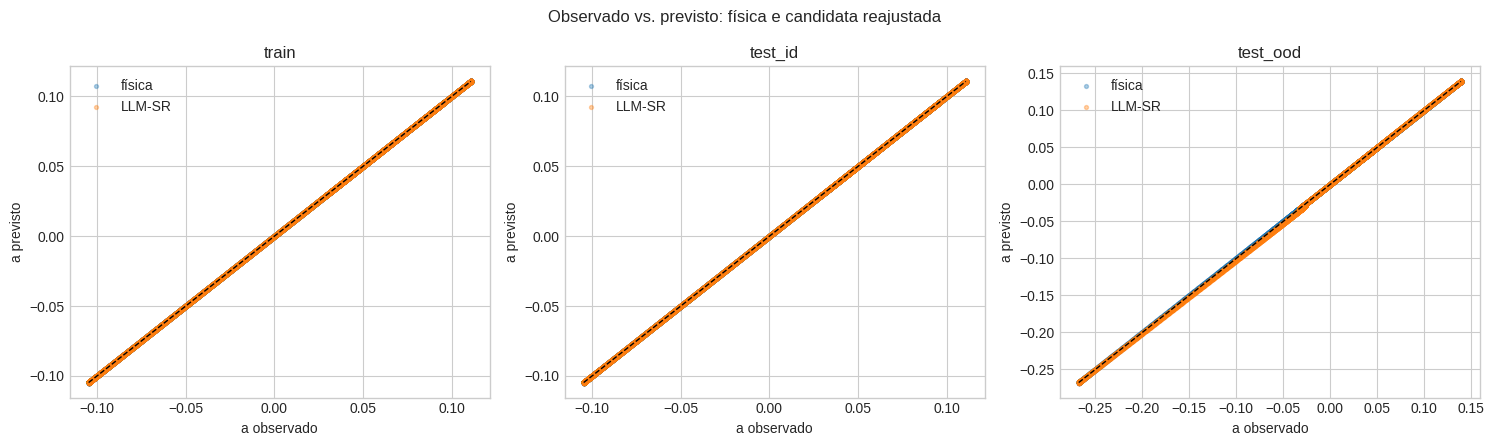

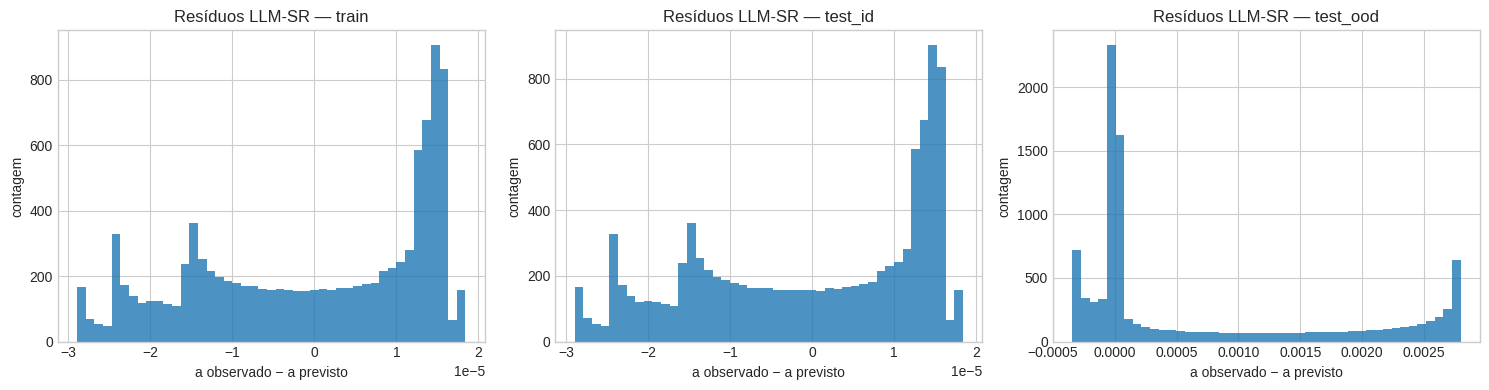

In [32]:
prediction_functions = {"equação física": lambda df: oscillator1_ground_truth(df.x.to_numpy(), df.v.to_numpy())}
if candidate_predict is not None:
    params_for_prediction = candidate_fit if candidate_fit is not None else np.empty(0)
    prediction_functions["LLM-SR (reajustada)"] = lambda df: candidate_predict(df.x.to_numpy(), df.v.to_numpy(), params_for_prediction)
if "pysr_model" in globals(): prediction_functions["PySR"] = lambda df: pysr_model.predict(df[["x", "v"]].to_numpy())
if "gp_model" in globals(): prediction_functions["gplearn"] = lambda df: gp_model.predict(df[["x", "v"]].to_numpy())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (split, df) in zip(axes, sets.items()):
    ax.scatter(df.a, oscillator1_ground_truth(df.x.to_numpy(), df.v.to_numpy()), s=8, alpha=.35, label="física")
    if candidate_predict is not None:
        try:
            pred = prediction_functions["LLM-SR (reajustada)"](df)
            ax.scatter(df.a, pred, s=8, alpha=.35, label="LLM-SR")
        except Exception as exc:
            print(f"Gráfico LLM-SR não disponível em {split}:", repr(exc))
    lo, hi = df.a.min(), df.a.max()
    ax.plot([lo,hi],[lo,hi],"k--",lw=1)
    ax.set(title=split, xlabel="a observado", ylabel="a previsto")
    ax.legend()
plt.suptitle("Observado vs. previsto: física e candidata reajustada")
plt.tight_layout(); plt.show()

if candidate_metrics:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, split in zip(axes, sets):
        df=sets[split]
        pred=prediction_functions["LLM-SR (reajustada)"](df)
        ax.hist(np.asarray(df.a)-np.asarray(pred), bins=45, alpha=.8)
        ax.set(title=f"Resíduos LLM-SR — {split}", xlabel="a observado − a previsto", ylabel="contagem")
    plt.tight_layout(); plt.show()


## Conclusão e limites

A tabela de métricas reavalia a melhor hipótese selecionada pelo score, mas **reajusta seus parâmetros no treino**, pois o log não preservou os valores originais. As métricas `test_id` e `test_ood` mostram generalização da forma simbólica reajustada; não devem ser confundidas com a validação da configuração exata que produziu o score registrado. Se a amostra usa sintaxe fora da gramática AST permitida, a seção numérica da candidata é ignorada com uma mensagem explicativa, enquanto a referência física e os baselines continuam funcionando.

PySR e gplearn são ajustados novamente quando disponíveis; seus resultados variam com a versão das bibliotecas e configurações nesta célula. O score do log é uma métrica histórica da busca e não substitui a comparação com as previsões dos CSVs.
